In [1]:
!pip install geopandas
!pip install geodatasets
!pip install contextily
!pip install geoplot
!pip install geopy
!pip install folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.6/64.6 kB 1.3 MB/s eta 0:00:00a 0:00:01


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import geopandas as gpd
import contextily as ctx
import geoplot.crs as gcrs
import geoplot as gplt
import pyproj

# NEW YORK

#### Inlezen van bestanden via geodatasets - NEW YORK

In [28]:
from geodatasets import get_path
path_to_file = get_path("nybb")

#### Afstanden berekenen - oefening

Schrijf een functie die voor een gegeven GeoDataFrame de afstandsmatrix (distance matrix) berekent voor de centroids van alle locaties.  Gebruik de .distance() functie.  Het resultaat is ongeveer als volgt:

![alt text](../IMAGES/distancematrix.png "Optionele titel")

In [13]:
# Oplossing


# VISUALISEREN VAN HET INKOMEN IN DE WERELD

In [29]:
## De wereld inladen
world = gpd.read_file('GEODATA/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')

Zoek in de dataset naar een property die te maken heeft met de inkomensgroep waartoe het land behoort.  Plot de wereldkaar en geef elk land een kleurtje in functie van deze parameter.

In [17]:
# Oplossing


# VISUALISATIE VAN DE BEVOLKINGSDICHTHEID IN DE WERELD

Gebruik de GeoDataset die je hierbocen hebt gebruikt om het inkomen in de wereld te visualiseren nu om de bevolkingsdichtheid in de wereld te visualiseren.  Zorg voor een passend kleurschema, en pas eventueel de schaal aan.  Ga ook na of het CRS geschikt is voor de opdracht.  Als opwarmer kan je even de populatiedichtheid in België berekenen:

Oppervlakte van België: 30125.663016421327 km²
Population in Belgium: 11484055.0
Population density in Belgium: 381.2050541008876 hab/km² 


In [105]:
# Nu voor alle landen...

                    SOVEREIGNT      area_km2      POP_EST  population_density
0                         Fiji  1.916776e+04     889953.0           46.429687
1  United Republic of Tanzania  9.335536e+05   58005463.0           62.134047
2               Western Sahara  9.586239e+04     603253.0            6.292906
3                       Canada  1.003334e+07   37589262.0            3.746435
4     United States of America  9.512162e+06  328239523.0           34.507353


     SOVEREIGNT      area_km2     POP_EST  population_density
129    Belgium  30125.663016  11484055.0          381.205054


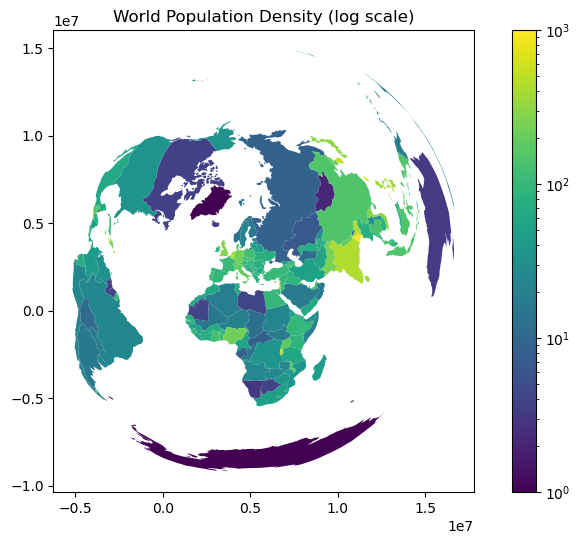

In [107]:
# Plot
from matplotlib.colors import LogNorm


# BELGIE

Zoek de GPS coördinaten voor de sites van Syntra in België.  Geef deze als punten weer op een kaart.  Gebruik de add_basemap functionaliteit van contextily.

#### Info mbt de dataset.  
admin_level of osm_admin_level geeft waarschijnlijk de administratieve niveaus aan. In OpenStreetMap wordt het administratieve niveau als volgt gebruikt:
admin_level = 8: Gemeentelijke grenzen.
admin_level = 6: Provinciale grenzen.
We kunnen dus proberen om alleen de rijen te selecteren waar het admin_level gelijk is aan 6, wat zou moeten overeenkomen met de provincies.  
- Gemeenten: 581
- Provincies: 10
- Gewesten: 3
- Gemeenschappen: 3

In [30]:
## Belgie
belgium = gpd.read_file('GEODATA/kontur_boundaries_BE_20230628.gpkg')

#### Lijst de provincies op uit de dataset.  Geef vervolgens een kaart weer met daarop enkel de provincies van België.

,admin_level,osm_admin_level,name,name_en,population,hasc,geometry
4,7,6,Brabant wallon,Walloon Brabant,410641.0,BE.BW,"MULTIPOLYGON (((4.09178 50.66914, 4.09453 50.6..."
5,7,6,Antwerpen,Antwerp,1845314.0,BE.AN,"MULTIPOLYGON (((4.17242 51.0923, 4.17245 51.09..."
6,7,6,Oost-Vlaanderen,East Flanders,1505010.0,BE.OV,"MULTIPOLYGON (((3.33131 51.09888, 3.33256 51.0..."
7,7,6,Vlaams-Brabant,Flemish Brabant,1146081.0,BE.VB,"MULTIPOLYGON (((3.88932 50.71155, 3.88932 50.7..."
8,7,6,Hainaut,Hainaut,1344745.0,BE.HT,"MULTIPOLYGON (((3.17858 50.75596, 3.17863 50.7..."
9,7,6,Namur,Namur,506683.0,BE.NA,"MULTIPOLYGON (((4.28593 50.24987, 4.28822 50.2..."
10,7,6,Luxembourg,Luxembourg,290727.0,BE.LX,"MULTIPOLYGON (((4.96855 49.80158, 4.96923 49.8..."
11,7,6,Liège,None,1120719.0,BE.LG,"MULTIPOLYGON (((4.97931 50.6186, 4.98158 50.61..."
12,7,6,West-Vlaanderen,West Flanders,1278821.0,BE.WV,"MULTIPOLYGON (((2.54136 51.09379, 2.54314 51.0..."
13,7,6,Limburg,Limburg,880422.0,BE.LI,"MULTIPOLYGON (((4.98008 51.0328, 4.98009 51.03..."


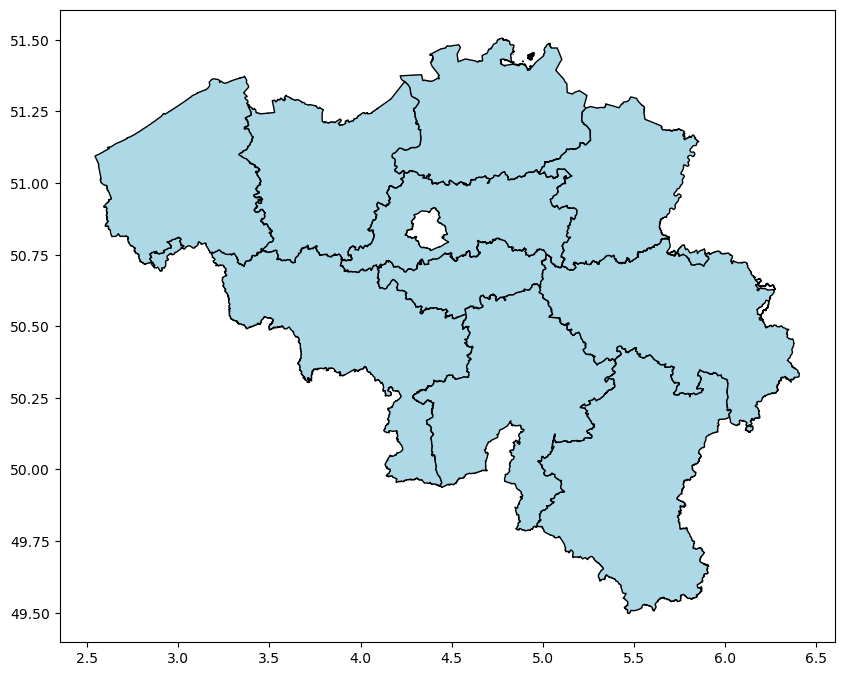

#### Omzetten van een adres naar een geocode
je kunt een adres omzetten naar geografische coördinaten (geocoderen) met behulp van verschillende online diensten zoals Geopy, Google Maps API, Nominatim (OpenStreetMap), en andere geocoding-tools. Hier is een voorbeeld met de Geopy-bibliotheek, die de Nominatim-service van OpenStreetMap gebruikt om een adres om te zetten naar coördinaten.

Bij het geocoderen met Geopy en de Nominatim-service (van OpenStreetMap), worden de coördinaten standaard geretourneerd in het EPSG:4326 coördinatenreferentiesysteem, ook bekend als WGS 84.

In [20]:
from geopy.geocoders import Nominatim

# Maak een geocoder object
geolocator = Nominatim(user_agent="geoapiExercises")

# Het adres dat je wilt geocoderen
address = "Spoorwegstraat 14, 8200 Brugge"

# Geocodeer het adres
location = geolocator.geocode(address)

# Print de coördinaten van het adres
if location:
    print(f"Geocodeerde coördinaten: Latitude: {location.latitude}, Longitude: {location.longitude}")
else:
    print("Adres niet gevonden")


Geocodeerde coördinaten: Latitude: 51.1924525, Longitude: 3.2193417


#### Geef alles sites van Syntra weer als punten op de kaart.  Zorg dat de kaart overzichtelijk blijft.

In [25]:
# Oplossing


#### Oefening: maak een kaart van Vlaanderen met daarin alle gemeentes.  Visualiseer het inkomen per gemeente met een geschikte kleur.

In [27]:
# Oplossing
